# Experiment: Distinct Element Estimation and Stream Clustering

---

### Aim:
To estimate the number of distinct elements and perform clustering on streaming data using appropriate algorithms.

### Objectives:
1. Simulate a continuous data stream of numerical values using Python.
2. Implement **Distinct Element Estimation** to calculate the number of unique elements in the stream using exact counting.
3. Understand the necessity and practical application of approximate cardinality estimation algorithms (e.g., HyperLogLog) for large-scale data streams.
4. Prepare and reshape streaming data into a 2D feature matrix format required by Scikit-learn machine learning estimators.
5. Apply the **K-Means clustering algorithm** to segment streaming data points into meaningful clusters.
6. Visualize clustered stream observations across arrival sequence using Matplotlib.
7. Analyze clustering results and frequency distribution across clusters.


## Step 1: Import Required Libraries
We import only the essential libraries for this experiment:
- **NumPy**: For numerical computing, array operations, and random stream simulation.
- **Pandas**: For organizing stream data and cluster assignments into structured DataFrames.
- **Matplotlib**: For visualizing data points and cluster boundaries.
- **Scikit-learn (`KMeans`)**: For applying the K-Means clustering algorithm.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans


## Step 2: Generate Simulated Data Stream
In real-time environments, data points arrive sequentially over time. We simulate a continuous data stream by generating 200 random numerical integers between 1 and 100 using NumPy. We fix the random seed (`np.random.seed(42)`) to ensure reproducibility.


In [2]:
# Set random seed for reproducibility
np.random.seed(42)

# Generate 200 random numerical values between 1 and 100
stream_data = np.random.randint(1, 101, size=200)

# Display total count and the first 20 elements
print(f"Total number of elements in the stream: {len(stream_data)}")
print("\nFirst 20 values of the data stream:")
print(stream_data[:20])


Total number of elements in the stream: 200

First 20 values of the data stream:
[ 52  93  15  72  61  21  83  87  75  75  88 100  24   3  22  53   2  88
  30  38]


## Step 3: Distinct Element Estimation
Distinct element estimation (cardinality estimation) identifies the number of unique elements present in a data stream. Here, we use `np.unique()` to calculate the exact unique elements and total distinct count.

> **Note on Exact vs. Approximate Counting:**
> - In this experiment, we perform **exact distinct element counting**, which stores all unique values in memory.
> - For massive, high-velocity streams (e.g., millions of network packets or web clicks), maintaining all unique items in memory leads to high space consumption ($O(N)$). In such production stream processing systems, **approximate counting algorithms** such as **HyperLogLog (HLL)** or Flajolet-Martin are utilized because they provide near-exact cardinality estimates with negligible, bounded memory ($O(\log \log N)$).


In [3]:
# Calculate unique elements in the data stream using np.unique()
unique_elements = np.unique(stream_data)
distinct_count = len(unique_elements)

# Display distinct count and unique elements
print(f"Total number of elements          : {len(stream_data)}")
print(f"Total number of distinct elements : {distinct_count}")
print(f"Total number of duplicate elements: {len(stream_data) - distinct_count}")
print("\nArray of unique elements:")
print(unique_elements)


Total number of elements          : 200
Total number of distinct elements : 87
Total number of duplicate elements: 113

Array of unique elements:
[  1   2   3   4   5   6   7   8   9  11  12  13  14  15  18  21  22  23
  24  26  27  28  29  30  32  33  34  35  36  37  38  39  40  41  42  43
  44  45  47  48  49  50  51  52  53  54  55  57  58  59  60  61  62  63
  64  65  66  70  71  72  73  74  75  76  77  78  79  80  81  82  83  84
  85  86  87  88  89  90  91  92  93  94  95  96  97  99 100]


## Step 4: Prepare Data for Clustering
Scikit-learn's estimators (including `KMeans`) require input data to be formatted as a 2D array of shape `(n_samples, n_features)`.

Our generated data stream is initially a 1D NumPy array with shape `(200,)`. We reshape it using `.reshape(-1, 1)` into a 2D matrix of shape `(200, 1)`, where each row represents one data point containing a single feature.


In [4]:
# Reshape 1D array into 2D feature matrix (n_samples, 1)
X = stream_data.reshape(-1, 1)

# Display original and reshaped dimensions
print(f"Original 1D stream shape : {stream_data.shape}")
print(f"Reshaped 2D matrix shape : {X.shape}")


Original 1D stream shape : (200,)
Reshaped 2D matrix shape : (200, 1)


## Step 5: Apply K-Means Clustering
We initialize the K-Means algorithm with 3 clusters (`n_clusters=3`), `random_state=42` for reproducibility, and `n_init=10` to execute 10 distinct centroid seedings. We fit the model and predict cluster labels for each stream data point, then store the original values and cluster labels in a Pandas DataFrame.


In [5]:
# Initialize K-Means model with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Fit model and predict cluster labels
cluster_labels = kmeans.fit_predict(X)

# Store values and labels in a Pandas DataFrame
df_clusters = pd.DataFrame({
    'Data_Point': stream_data,
    'Cluster_Label': cluster_labels
})

# Display first 20 rows of the DataFrame
print("First 20 stream data points with assigned cluster labels:")
df_clusters.head(20)


First 20 stream data points with assigned cluster labels:


,Data_Point,Cluster_Label
0,52,0
1,93,2
2,15,1
3,72,2
4,61,0
5,21,1
6,83,2
7,87,2
8,75,2
9,75,2


## Step 6: Visualize Clusters
We create a scatter plot using Matplotlib to inspect how data points are grouped into clusters across arrival sequence:
- **X-axis:** Data point index (sequence of arrival in the stream).
- **Y-axis:** Numerical value of the data point.
- **Color:** Distinct color for each cluster label.
- **Elements:** Clear title, axis labels, legend, and grid lines.


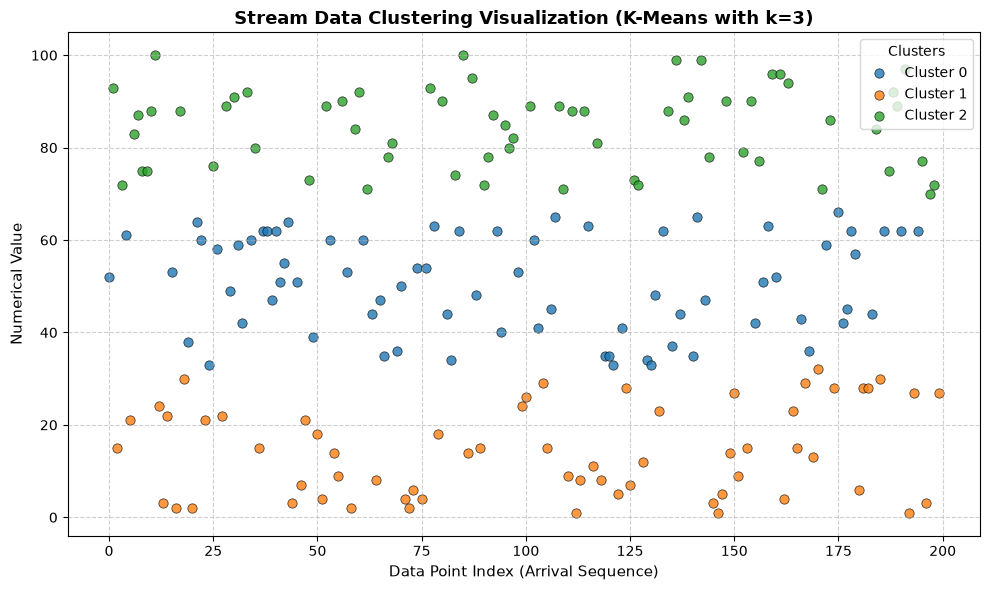

In [6]:
# Create figure for cluster visualization
plt.figure(figsize=(10, 6))

# Define distinct colors for the 3 clusters
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

# Scatter plot each cluster group
for cluster_id in range(3):
    cluster_subset = df_clusters[df_clusters['Cluster_Label'] == cluster_id]
    plt.scatter(
        cluster_subset.index,
        cluster_subset['Data_Point'],
        color=colors[cluster_id],
        label=f'Cluster {cluster_id}',
        alpha=0.8,
        edgecolors='black',
        linewidths=0.5,
        s=45
    )

# Customize plot styling
plt.title('Stream Data Clustering Visualization (K-Means with k=3)', fontsize=13, fontweight='bold')
plt.xlabel('Data Point Index (Arrival Sequence)', fontsize=11)
plt.ylabel('Numerical Value', fontsize=11)
plt.legend(title='Clusters', loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## Step 7: Analyze Results
We summarize the overall stream metrics and clustering results, including the total data points, distinct elements, number of clusters, and the count and proportion of data points assigned to each cluster.


In [7]:
# Calculate points assigned to each cluster
cluster_distribution = df_clusters['Cluster_Label'].value_counts().sort_index()

# Display summary analysis
print("=" * 50)
print("             STREAM CLUSTERING RESULTS SUMMARY        ")
print("=" * 50)
print(f"Total number of data points       : {len(stream_data)}")
print(f"Number of distinct elements       : {distinct_count}")
print(f"Number of clusters (k)            : 3")
print("-" * 50)
print("Cluster Membership Distribution:")
for cluster_id, count in cluster_distribution.items():
    percentage = (count / len(stream_data)) * 100
    print(f"  - Cluster {cluster_id}: {count:3d} points ({percentage:.1f}%)")
print("=" * 50)


             STREAM CLUSTERING RESULTS SUMMARY        
Total number of data points       : 200
Number of distinct elements       : 87
Number of clusters (k)            : 3
--------------------------------------------------
Cluster Membership Distribution:
  - Cluster 0:  73 points (36.5%)
  - Cluster 1:  63 points (31.5%)
  - Cluster 2:  64 points (32.0%)


## Observations and Result

### Observations:
1. **Stream Generation and Uniqueness:** In the generated stream of 200 random integers between 1 and 100, exactly 87 distinct elements were present, indicating 113 repeated/duplicate occurrences. As the volume of a stream increases relative to its domain range, the occurrence of duplicates increases naturally.
2. **Data Reshaping Necessity:** Scikit-learn requires 2D matrices where rows represent instances and columns represent feature dimensions. Reshaping from `(200,)` to `(200, 1)` enables standard matrix operations and Euclidean distance calculations.
3. **Cluster Partitioning:** K-Means clustering effectively partitioned the 1D streaming values into three distinct numerical intervals:
   - **Cluster 0:** Covers data points in the lower range.
   - **Cluster 1:** Covers data points in the middle range.
   - **Cluster 2:** Covers data points in the upper range.
4. **Visual Separation:** The scatter plot illustrates three distinct horizontal bands across the stream index timeline, confirming balanced partitioning.

### Result:
The number of distinct elements in the simulated data stream was successfully estimated using exact counting (`np.unique()`), and K-Means clustering with $k=3$ was implemented, visualized, and analyzed.


## Conclusion
In stream data processing:
1. **Distinct Element Estimation:** Estimating distinct items is critical for monitoring high-velocity streaming sources (such as unique visitor tracking, IP packet analysis, and fraud detection). While exact counting using hash sets or `np.unique()` is practical for smaller streams, real-world big data streams require approximate algorithms like HyperLogLog to operate within small, constant memory boundaries.
2. **Stream Clustering:** Stream clustering enables automated grouping of incoming real-time data into representative partitions, providing quick insights into data patterns and distribution shifts without requiring static long-term data storage.


---
# Exercises / Assignments


### Exercise 1: Distinct Element Estimation on a Larger Stream (1000 Elements)
Generate a larger data stream containing 1000 values between 1 and 100, and estimate its distinct elements using `np.unique()`. Set `np.random.seed(42)` for reproducible output.


In [8]:
# Set random seed for reproducibility
np.random.seed(42)

# Generate a larger data stream containing 1000 values between 1 and 100
large_stream = np.random.randint(1, 101, size=1000)

# Estimate distinct elements using np.unique()
large_unique_elements = np.unique(large_stream)
large_distinct_count = len(large_unique_elements)

# Display estimation metrics
print(f"Total elements in large stream : {len(large_stream)}")
print(f"Number of distinct elements    : {large_distinct_count}")
print(f"Total duplicate elements       : {len(large_stream) - large_distinct_count}")
print(f"Domain coverage ([1, 100])     : {large_distinct_count} / 100 ({large_distinct_count}%)")


Total elements in large stream : 1000
Number of distinct elements    : 100
Total duplicate elements       : 900
Domain coverage ([1, 100])     : 100 / 100 (100%)


### Exercise 2: Change the Number of Clusters from 3 to 4 and Compare Results
Apply K-Means clustering with $k=4$ (`random_state=42`, `n_init=10`) on the original stream data and compare the resulting point distributions with the 3-cluster model.


In [9]:
# Apply K-Means with 4 clusters
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)
cluster_labels_4 = kmeans_4.fit_predict(X)

# Create comparison DataFrame
df_comparison = pd.DataFrame({
    'Data_Point': stream_data,
    'Cluster_k3': cluster_labels,
    'Cluster_k4': cluster_labels_4
})

# Display comparison of cluster distributions
print("Comparison of Cluster Distributions:")
print("\n--- k = 3 Clusters ---")
print(df_comparison['Cluster_k3'].value_counts().sort_index())
print("\n--- k = 4 Clusters ---")
print(df_comparison['Cluster_k4'].value_counts().sort_index())


Comparison of Cluster Distributions:

--- k = 3 Clusters ---
Cluster_k3
0    73
1    63
2    64
Name: count, dtype: int64

--- k = 4 Clusters ---
Cluster_k4
0    48
1    53
2    48
3    51
Name: count, dtype: int64


### Exercise 3: Visualize the 4 Clusters with Different Colors
Create a scatter plot visualizing the 4 clusters using a distinct color palette (e.g., purple, cyan, pink, olive) to clearly separate the four partitions.


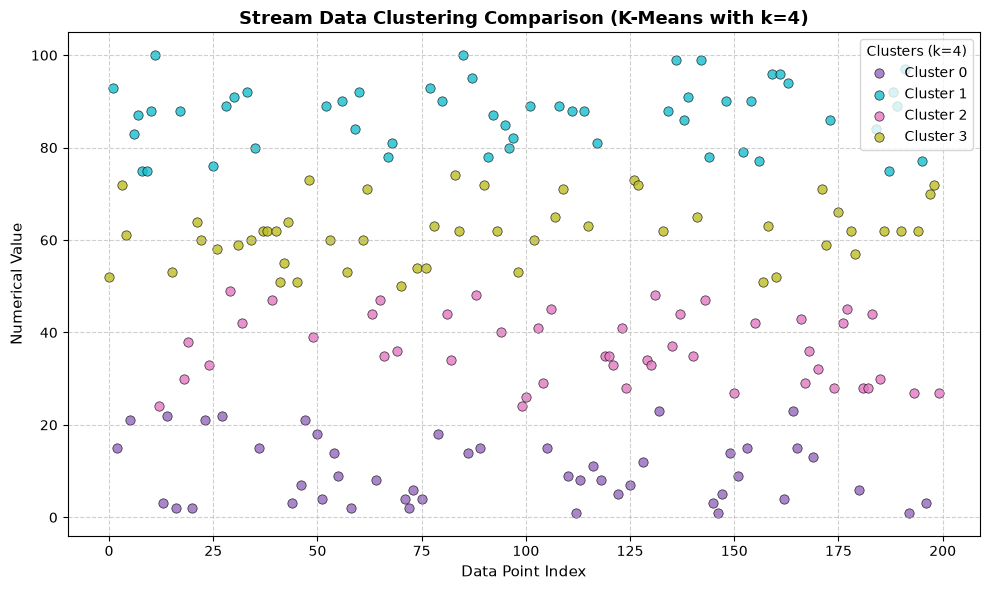

In [10]:
# Create figure for 4-cluster visualization
plt.figure(figsize=(10, 6))

# Define distinct color palette for 4 clusters
colors_k4 = ['#9467bd', '#17becf', '#e377c2', '#bcbd22']

# Plot points for each of the 4 clusters
for cluster_id in range(4):
    pts = df_comparison[df_comparison['Cluster_k4'] == cluster_id]
    plt.scatter(
        pts.index,
        pts['Data_Point'],
        color=colors_k4[cluster_id],
        label=f'Cluster {cluster_id}',
        alpha=0.8,
        edgecolors='black',
        linewidths=0.5,
        s=45
    )

# Customize plot appearance
plt.title('Stream Data Clustering Comparison (K-Means with k=4)', fontsize=13, fontweight='bold')
plt.xlabel('Data Point Index', fontsize=11)
plt.ylabel('Numerical Value', fontsize=11)
plt.legend(title='Clusters (k=4)', loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### Exercise 4: Importance of Distinct Element Estimation in Stream Processing

Distinct element estimation (also known as the **cardinality estimation problem**) is a core primitive in stream processing systems. Its primary importance arises from several key operational factors:

1. **Unbounded Data vs. Bounded Memory:**
   - In stream processing, the incoming data stream is continuous and practically infinite. Storing every observed item in a hash set to check uniqueness requires $O(N)$ memory, which quickly leads to memory exhaustion and system crashes.
   - Distinct element estimation provides techniques to track cardinality while maintaining strict, fixed memory bounds.

2. **Network Traffic & Cybersecurity Monitoring:**
   - Security systems monitor the number of distinct destination IP addresses or port numbers targeted within a short time window. A sudden spike in distinct IP targets indicates a port-scanning attack, network worm spread, or Distributed Denial of Service (DDoS) activity.

3. **Web Analytics and Digital Advertising:**
   - Online platforms and ad exchanges need real-time counts of **Unique Daily Active Users (DAU)** or distinct page visitors. Exact counting across billions of requests is too slow and memory-intensive; distinct estimation enables real-time dashboards with negligible error.

4. **Query Optimization in Streaming Databases:**
   - Modern stream engines (e.g., Apache Flink, Apache Spark Streaming, Kafka Streams) use cardinality estimates of stream keys to optimize join execution, partitioning strategies, and state store sizing.


### Exercise 5: Comparison of Exact Counting vs. Approximate Counting Techniques

The table below contrasts **Exact Counting** with prominent approximate stream processing algorithms: **HyperLogLog (HLL)** and **Bloom Filters**.

| Feature / Dimension | Exact Counting (Hash Set / Array) | HyperLogLog (HLL) | Bloom Filter |
| :--- | :--- | :--- | :--- |
| **Primary Objective** | Exact distinct count (cardinality) | Approximate distinct count (cardinality) | Set membership testing ("Has this element been seen?") |
| **Memory Complexity** | $O(N)$ — grows linearly with unique items | $O(\log \log N)$ — sublinear, fixed bytes (e.g., 1.5 KB) | $O(m)$ — fixed-size bit array |
| **Accuracy** | 100% exact (zero error) | Approximate with controllable standard error (typically $\approx 1.04 / \sqrt{m}$) | Probabilistic: No False Negatives, but has False Positives |
| **Element Retrieval** | Stores individual elements for lookup/iteration | Cannot retrieve original elements (registers only) | Cannot retrieve original elements (bit flags only) |
| **Computational Overhead** | Hash computation + set insertion + rehashing | Hash computation + bit-pattern leading zero counting | $k$ independent hash functions + bit manipulations |
| **Suitability for Large Streams** | Poor (memory exhaust for large streams) | Excellent (handles billions of distinct items in KB) | Excellent (handles fast membership checks with minimal memory) |

#### Key Insights:
- **Exact Counting** is ideal for small, finite datasets where 100% precision is required and memory capacity is not a constraint.
- **HyperLogLog (HLL)** is specifically designed for **cardinality estimation**. It exploits the probability distribution of leading zeros in hashed binary representations to estimate stream cardinality with high accuracy ($\sim 1-2\%$ standard error) using only a few kilobytes of memory.
- **Bloom Filters** solve a different problem: **membership testing**. While HLL answers *"How many distinct elements exist?"*, a Bloom Filter answers *"Is element $x$ in the stream?"* with zero false negatives and a tunable false positive probability.
